# K vecinos más cercanos desde cero

Elias de Jesus Zuñiga de Leon · Matrícula 2430085

Clasificador manual sobre 360 observaciones sintéticas de longitud y ancho de semillas. No se utiliza un clasificador KNN de scikit-learn.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)

Python: 3.12.14
NumPy: 2.5.5


## 1. Datos y partición

Se generan tres grupos solapados con semilla fija. La partición estratificada es 60% entrenamiento, 20% validación y 20% prueba.

In [2]:
from ia_unidad3 import knn
record, models = knn.experiment(2430085)
for name, indices in record['indices'].items(): print(name, len(indices))
print('Clases:', knn.LABELS)
print('Primeras observaciones:', record['x'][:3])

entrenamiento 216
validacion 72
prueba 72
Clases: ['Arroz', 'Cebada', 'Trigo']
Primeras observaciones: [[5.170323138344552, 1.82529679710026], [4.417933915640937, 2.1003947998439405], [4.420324349404485, 2.088440617088106]]


## 2. Distancias y decisión

Euclidiana: raíz de la suma de cuadrados. Manhattan: suma de diferencias absolutas. Mixta: suma de las dos anteriores. El escalador se ajusta únicamente con entrenamiento al elegir k; luego se reajusta con entrenamiento más validación. Los empates de votos se resuelven por suma de distancias y después por orden de clase.

In [3]:
for name in knn.METRICS: print(name, 'entre (0,0) y (3,4):', knn.distances([0,0], [[3,4]], name)[0])
for name, result in record['resultados'].items():
    print(name, 'k:', result['k'], 'exactitud:', round(result['prueba']['accuracy'],4), 'F1 macro:', round(result['prueba']['f1_macro'],4))

Euclidiana entre (0,0) y (3,4): 5.0
Manhattan entre (0,0) y (3,4): 7.0
Mixta entre (0,0) y (3,4): 12.0
Euclidiana k: 13 exactitud: 0.7083 F1 macro: 0.7032
Manhattan k: 13 exactitud: 0.7222 F1 macro: 0.7173
Mixta k: 13 exactitud: 0.7083 F1 macro: 0.7032


## 3. Selección de k con validación

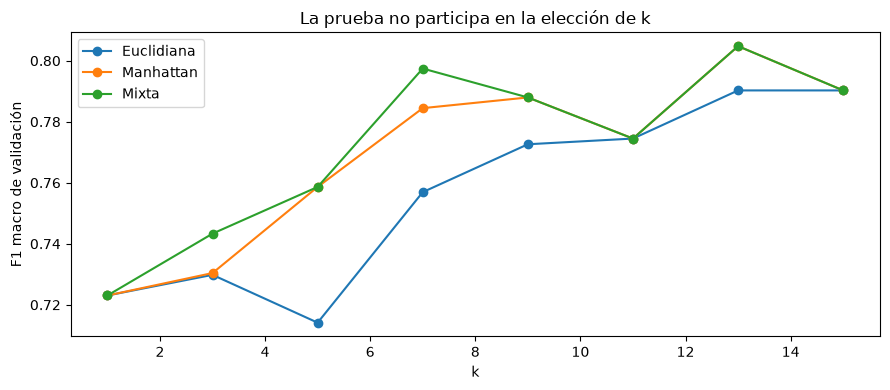

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, result in record['resultados'].items():
    curve = result['validacion']
    ax.plot([r['k'] for r in curve], [r['f1_macro'] for r in curve], marker='o', label=name)
ax.set(xlabel='k', ylabel='F1 macro de validación', title='La prueba no participa en la elección de k')
ax.legend(); plt.tight_layout(); plt.show()

## 4. Regiones de decisión y matrices de confusión

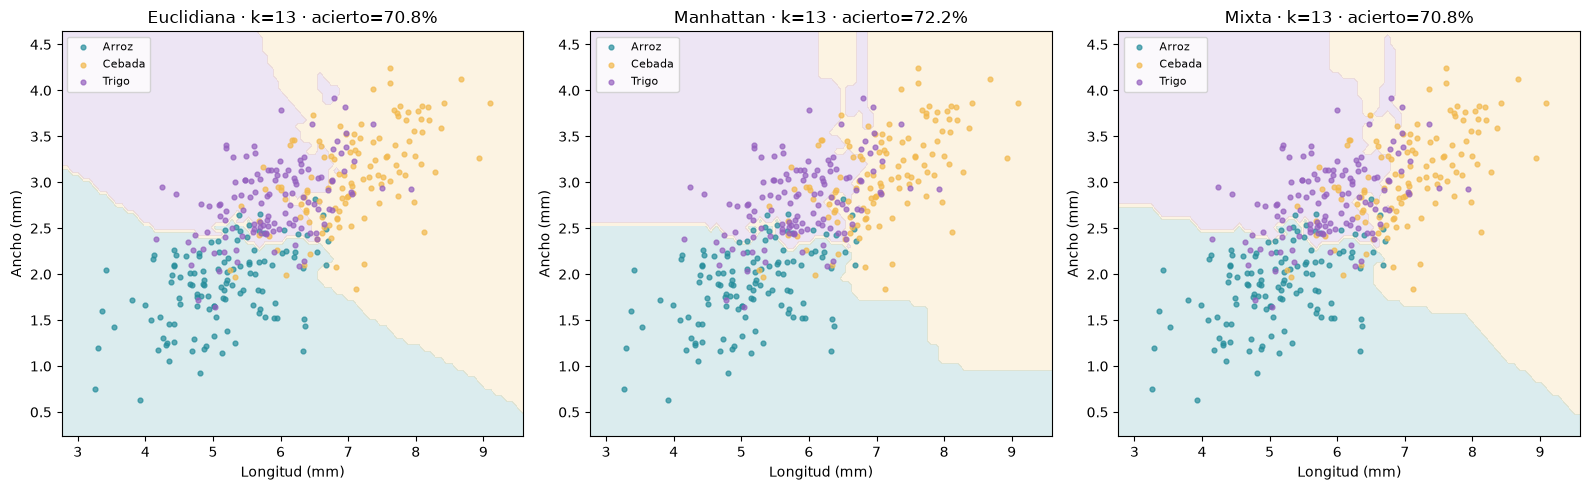

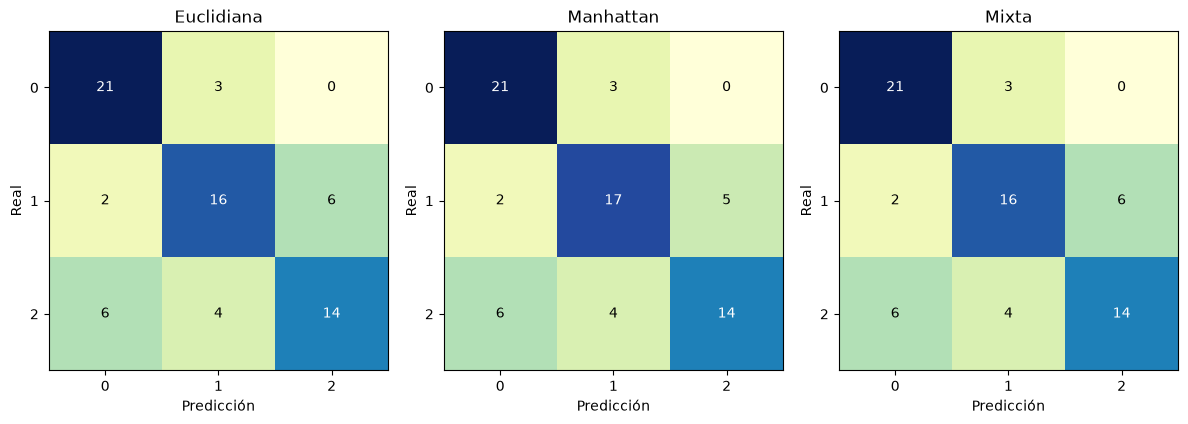

In [5]:
fig = plt.figure(figsize=(16, 5))
knn.draw_regions(fig, record, models)
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, name in zip(axes, knn.METRICS):
    matrix = np.array(record['resultados'][name]['prueba']['confusion'])
    ax.imshow(matrix, cmap='YlGnBu')
    for (r,c), v in np.ndenumerate(matrix): ax.text(c,r,str(v),ha='center',va='center',color='white' if v>matrix.max()/2 else 'black')
    ax.set(title=name, xlabel='Predicción', ylabel='Real', xticks=range(3), yticks=range(3))
plt.tight_layout(); plt.show()

## 5. Nuevo punto y conservación del experimento

In [6]:
PUNTO = [6.2, 2.6]
for name, model in models.items():
    selected, distances = model.neighbors(PUNTO)
    print(name, '→', knn.LABELS[model.predict_one(PUNTO)])
    print('Vecinos:', selected.tolist(), 'distancias:', distances.round(3).tolist())
knn.export_experiment(Path('resultados/cuaderno'), record, models)
print('Modelo, particiones y predicciones exportados.')

Euclidiana → Trigo
Vecinos: [171, 25, 137, 242, 202, 154, 108, 82, 184, 166, 80, 194, 64] distancias: [0.014, 0.081, 0.088, 0.097, 0.153, 0.173, 0.185, 0.215, 0.219, 0.226, 0.236, 0.247, 0.305]
Manhattan → Trigo
Vecinos: [171, 25, 242, 137, 202, 154, 108, 166, 80, 82, 184, 194, 271] distancias: [0.016, 0.104, 0.105, 0.125, 0.214, 0.24, 0.257, 0.274, 0.281, 0.3, 0.309, 0.318, 0.365]
Mixta → Trigo
Vecinos: [171, 25, 242, 137, 202, 154, 108, 166, 82, 80, 184, 194, 271] distancias: [0.03, 0.186, 0.203, 0.213, 0.367, 0.413, 0.442, 0.5, 0.514, 0.518, 0.528, 0.566, 0.722]
Modelo, particiones y predicciones exportados.


## Conclusiones

Las tres distancias tienen resultados cercanos en esta muestra, con errores por el solapamiento de clases. Las métricas corresponden a datos sintéticos y a una única partición. La proporción de votos no se interpreta como probabilidad calibrada.